# Lab 7 · SMS Spam Detection with a Bidirectional LSTM
### Deep Learning Laboratory (23DS5PCDLG)
**Name:** Kartikey Agrawal &nbsp;·&nbsp; **USN:** 1BM24CD028

Classify SMS messages as **spam** or **ham** using Embedding → Bidirectional LSTM → Dense (sigmoid).

## Task 1 — Load and explore the dataset

In [1]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import TextVectorization, Embedding, LSTM, Bidirectional, Dense, Dropout
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [2]:
path = tf.keras.utils.get_file(
    "sms_spam.zip", "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip")
with zipfile.ZipFile(path) as z:
    with z.open("SMSSpamCollection") as f:
        df = pd.read_csv(f, sep="\t", names=["label", "message"])

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print(df["label"].value_counts())
df.head()

Shape: (5572, 2)
Missing values: 0
label
ham     4825
spam     747
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Length -> min: 2, max: 910, mean: 80.5

Ham : Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
Spam: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's


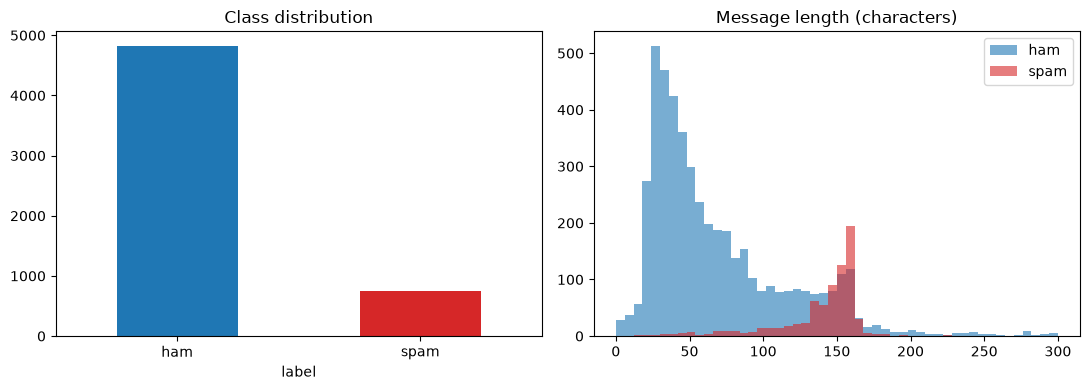

In [3]:
df["length"] = df["message"].str.len()
print(f"Length -> min: {df.length.min()}, max: {df.length.max()}, mean: {df.length.mean():.1f}")
print("\nHam :", df[df.label == "ham"].message.iloc[0])
print("Spam:", df[df.label == "spam"].message.iloc[0])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["label"].value_counts().plot.bar(ax=ax[0], color=["tab:blue", "tab:red"], rot=0)
ax[0].set_title("Class distribution")
for lbl, col in [("ham", "tab:blue"), ("spam", "tab:red")]:
    ax[1].hist(df[df.label == lbl].length, bins=50, range=(0, 300), alpha=0.6, label=lbl, color=col)
ax[1].set_title("Message length (characters)"); ax[1].legend()
plt.tight_layout(); plt.show()

## Task 2 — Preprocess the text

In [4]:
X = df["message"].values
y = (df["label"] == "spam").astype(int).values   # spam = 1, ham = 0

# stratified 80 / 10 / 10 split keeps the spam ratio the same in every set
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=42)
print("train / val / test:", len(X_train), len(X_val), len(X_test))
print(f"spam ratio: {y_train.mean():.3f} / {y_val.mean():.3f} / {y_test.mean():.3f}")

train / val / test: 4457 557 558
spam ratio: 0.134 / 0.133 / 0.134


In [5]:
vocab_size, maxlen = 10000, 100

vectorizer = TextVectorization(max_tokens=vocab_size, output_sequence_length=maxlen)
vectorizer.adapt(X_train)          # fit vocabulary on training data only

X_train_seq = vectorizer(X_train)
X_val_seq   = vectorizer(X_val)
X_test_seq  = vectorizer(X_test)
print("Padded shape:", X_train_seq.shape)

Padded shape: (4457, 100)


## Task 3 — Build the model

In [6]:
model = Sequential([
    Input(shape=(maxlen,)),
    Embedding(vocab_size, 64),
    Bidirectional(LSTM(64)),
    Dropout(0.5),
    Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 706,177 (2.69 MB)

 Trainable params: 706,177 (2.69 MB)

 Non-trainable params: 0 (0.00 B)

**Why is the BiLSTM output 2 × units?** One LSTM reads left-to-right and another right-to-left; their final states (64 each) are concatenated, giving 128.

## Task 4 — Train and evaluate

In [7]:
history = model.fit(X_train_seq, y_train, validation_data=(X_val_seq, y_val),
                    epochs=8, batch_size=32)

Epoch 1/8


  1/140 ━━━━━━━━━━━━━━━━━━━━ 2:31 1s/step - accuracy: 0.4062 - loss: 0.6947

  6/140 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7708 - loss: 0.6304

 11/140 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8068 - loss: 0.5492

 16/140 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8301 - loss: 0.4819

 21/140 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8348 - loss: 0.4555

... (230 outputs left out)

126/140 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9998 - loss: 0.0012

131/140 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9998 - loss: 0.0012

136/140 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9998 - loss: 0.0012

140/140 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9998 - loss: 0.0012 - val_accuracy: 0.9820 - val_loss: 0.0981


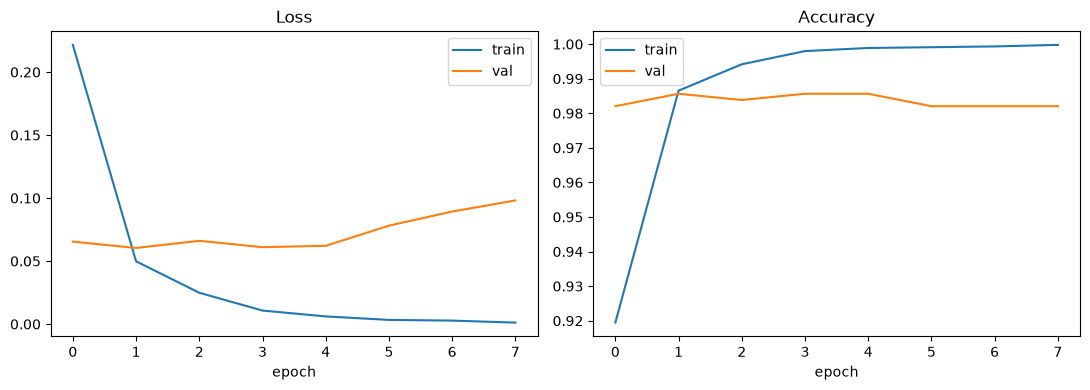

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for i, m in enumerate(["loss", "accuracy"]):
    ax[i].plot(history.history[m], label="train")
    ax[i].plot(history.history["val_" + m], label="val")
    ax[i].set_title(m.capitalize()); ax[i].set_xlabel("epoch"); ax[i].legend()
plt.tight_layout(); plt.show()

Test accuracy: 98.75%


              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       483
        spam       0.99      0.92      0.95        75

    accuracy                           0.99       558
   macro avg       0.99      0.96      0.97       558
weighted avg       0.99      0.99      0.99       558



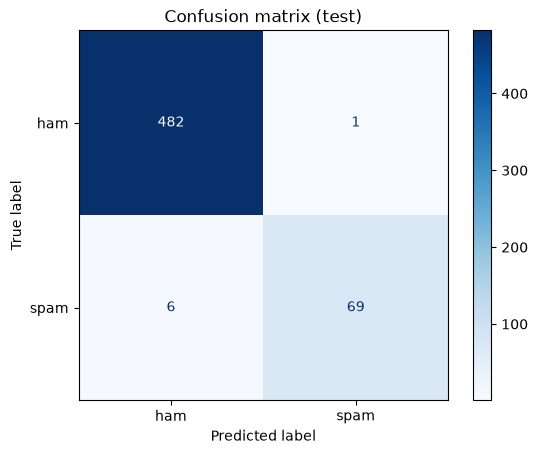

In [9]:
loss, acc = model.evaluate(X_test_seq, y_test, verbose=0)
print(f"Test accuracy: {acc*100:.2f}%")

y_pred = (model.predict(X_test_seq, verbose=0).ravel() >= 0.5).astype(int)
print(classification_report(y_test, y_pred, target_names=["ham", "spam"]))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["ham", "spam"], cmap="Blues")
plt.title("Confusion matrix (test)"); plt.show()

## Task 5 — Predict new messages

In [10]:
def predict(text):
    p = model.predict(vectorizer([text]), verbose=0)[0][0]
    return ("Spam" if p >= 0.5 else "Ham"), p

samples = [
    "Congratulations! You have won a free iPhone. Click the link to claim now",
    "Are we meeting at the library at 5 today?",
    "URGENT: your account is suspended, call 0800123456 to reactivate",
    "Can you send me the notes from today's lecture",
    "Win cash prizes every week! Text WIN to 80085",
]
for s in samples:
    label, p = predict(s)
    print(f"{label:4s} (p_spam={p:.2f})  <- {s}")

Spam (p_spam=1.00)  <- Congratulations! You have won a free iPhone. Click the link to claim now
Ham  (p_spam=0.00)  <- Are we meeting at the library at 5 today?
Ham  (p_spam=0.35)  <- URGENT: your account is suspended, call 0800123456 to reactivate
Ham  (p_spam=0.00)  <- Can you send me the notes from today's lecture
Spam (p_spam=1.00)  <- Win cash prizes every week! Text WIN to 80085


## Summary questions

1. **Why padding?** A batch must be a fixed-shape tensor, so every message is padded/truncated to 100 tokens.
2. **Why embeddings over one-hot?** Embeddings are small, dense and learned, so similar words get similar vectors; one-hot is huge and sparse and treats all words as unrelated.
3. **Why Bidirectional LSTM?** It reads the message both ways, so each word's context from before and after is used.
4. **Why sigmoid + binary crossentropy?** It's a 2-class problem; one sigmoid unit outputs P(spam) and binary crossentropy is the matching loss.
5. **Why is accuracy misleading?** Only ~13% of messages are spam, so always predicting "ham" already gives ~87%. That's why we also check precision, recall and F1 for the spam class.